# Statistical GAM validation

This report surveys parser, family, shape-constraint, smoothing-selection,
and inference interfaces. Finite predictions and constructed terms are
interface checks, not generalization estimates. For the fitted teaching
workflow with held-out data, use [Statistical GAMs in depth](../../notebooks/02_statistical_gams.ipynb).


**Execution environment:** nampy 0.3.0, numpy 1.26.4, scikit-learn 1.9.0, torch 2.14.1+cpu, lightning 2.6.6. Python 3.12.13; source revision `638ae3d3aeb991c46a6e144904357977c9c7fcac`; source-content SHA256 `caf2f8090e40248b953adec42765591b1a05ede3cfa4af60a485e14316d34013` (includes local source changes); elapsed 31.9 seconds on this CPU. Runtime varies by hardware.

## 1. Penalized regression splines

A smooth is represented by basis functions,
$f_j(x)=\sum_{r=1}^{K_j}b_{jr}(x)\beta_{jr}$. With model matrix $B$, the
additive predictor becomes $B\beta$. Penalized likelihood estimates the
coefficients by minimizing

$$-\ell(\beta;y)+\frac12\sum_j\lambda_j\beta^\top S_j\beta.$$

$S_j$ measures a type of roughness, while $\lambda_j$ controls its cost.
Large $\lambda_j$ suppresses penalized variation; small values allow a more
flexible fit. The basis dimension $K_j$ limits the available function space,
whereas the effective degrees of freedom describe how much flexibility the
penalized fit actually uses. Increasing `k` is therefore different from
reducing the smoothing penalty.


## 2. Example data


In [1]:
import time
import logging
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
logging.getLogger("lightning.pytorch").setLevel(logging.ERROR)
plt.style.use("seaborn-v0_8-whitegrid")
COLORS = ["#2563EB", "#F97316", "#10B981", "#8B5CF6", "#EF4444"]

N_SAMPLES = 1000
RANDOM_STATE = 7

rng = np.random.default_rng(RANDOM_STATE)

n = N_SAMPLES
x1 = rng.uniform(0.0, 1.0, n)
x2 = rng.uniform(-1.0, 1.0, n)
season = rng.uniform(0.0, 24.0, n)
group = pd.Categorical(rng.choice(["a", "b", "c", "d"], size=n))
group_effect = pd.Series(group).map({"a": -0.5, "b": 0.2, "c": 0.8, "d": -0.1}).astype(float).to_numpy()
surface = 0.9 * np.sin(np.pi * x1) * np.cos(np.pi * x2)
mu = 1.2 + np.sin(2 * np.pi * x1) + 0.35 * x2 + surface + group_effect
exposure = rng.uniform(0.5, 2.5, n)

data = pd.DataFrame({
    "x1": x1, "x2": x2, "season": season, "group": group,
    "exposure": exposure, "log_exposure": np.log(exposure),
})
data["y"] = mu + rng.normal(0.0, 0.25, n)
data["binary"] = rng.binomial(1, 1 / (1 + np.exp(-(-0.5 + mu))))
rate = np.exp(0.2 + 0.7 * np.sin(2 * np.pi * x1)) * exposure
data["count"] = rng.poisson(rate)
data["gamma"] = rng.gamma(shape=6.0, scale=np.exp(0.4 + 0.4 * x1) / 6.0)
data["beta"] = np.clip(rng.beta(2.0 + 2.0 * x1, 3.0), 1e-5, 1 - 1e-5)
data["ordinal"] = pd.cut(mu, bins=[-np.inf, 0.8, 1.6, 2.4, np.inf], labels=False) + 1
data["positive"] = np.maximum(0.0, rng.gamma(2.0, 0.5, n) - 0.35)

sigma = np.exp(-1.3 + 0.7 * (x2 + 1) / 2)
data["hetero"] = 1.0 + np.sin(2 * np.pi * x1) + sigma * rng.normal(size=n)
data["gamma_lss"] = rng.gamma(shape=1 / 0.25**2, scale=np.exp(0.2 + 0.5 * x1) * 0.25**2)
data.head()


,x1,x2,season,group,exposure,log_exposure,y,binary,count,gamma,beta,ordinal,positive,hetero,gamma_lss
0,0.625095,0.738100,5.557914,c,1.324164,0.280781,0.966891,1,0,1.970169,0.787014,2,0.191511,1.062767,1.505242
1,0.897214,0.755747,11.822085,a,2.317078,0.840307,-0.159248,0,2,1.754693,0.446612,1,0.519533,1.067378,2.324904
2,0.775686,0.243817,22.611809,b,2.439094,0.891627,0.914820,1,2,2.652471,0.672104,2,0.000000,-0.404634,2.147557
3,0.225207,0.042613,17.492449,d,2.329549,0.845675,2.805302,1,7,1.816914,0.241851,4,0.000000,2.102655,1.666436
4,0.300166,-0.599150,13.535336,a,1.322027,0.279166,1.269649,1,6,3.225496,0.745565,2,3.478180,2.032739,1.110655


## 3. Fit GAMs with formulas or arrays

Formula mode preserves named parametric terms, categorical contrasts,
smooth specifications, offsets, and multi-predictor formulas. Array mode
is compact and sklearn-friendly: each input column receives the adapter's
common basis and dimension. Use formula mode when terms need different
bases or structured effects.


In [2]:
from nampy.gam import GAM
from nampy.models import GAMClassifier, GAMLSS, GAMRegressor

formula_gam = GAM(
    optimize_smoothing=True,
    formula="y ~ x2 + group + s(x1, bs='cr', k=10) + s(season, bs='cc', k=8)",
    family="gaussian",
    smoothing_method="reml",
).fit(data=data)

array_gam = GAMRegressor(k=9, basis="cr", smoothing_method="reml").fit(
    data[["x1", "x2"]], data["y"]
)

formula_prediction, formula_se = formula_gam.predict(data, type="response", return_se=True)
array_prediction = array_gam.predict(data[["x1", "x2"]])
display(formula_gam.summary())
display(pd.DataFrame({
    "interface": ["formula", "array"],
    "prediction shape": [formula_prediction.shape, array_prediction.shape],
    "intercept": [
        formula_gam.fit_result(include_covariances=False).intercept,
        array_gam.gam_.fit_result(include_covariances=False).intercept,
    ],
}))



Family: gaussian
Link function: identity

Formula:
y ~ x2 + group + s(x1, bs='cr', k=10) + s(season, bs='cc', k=8)

Parametric coefficients:
                 Estimate   Std. Error      t value     Pr(>|t|)    
(Intercept)       0.71472     0.032341       22.099       <2e-16 ***
x2                0.30726     0.028121       10.927       <2e-16 ***
group[b]          0.69784     0.045243       15.424       <2e-16 ***
group[c]           1.3031     0.046353       28.113       <2e-16 ***
group[d]          0.38193     0.045162       8.4568       <2e-16 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Approximate significance of smooth terms:
                      edf       Ref.df            F      p-value    
s(x1)              7.4832       8.4239       227.35       <2e-16 ***
s(season)          1.7213            6      0.82139      0.03936 *
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

R-sq.(adj) = 0.744   Deviance explained = 74.7%
-REML = 761.5

GAMSummary(family_name='gaussian', link_name='identity', formula="y ~ x2 + group + s(x1, bs='cr', k=10) + s(season, bs='cc', k=8)", p_coeff=array([0.71471547, 0.30726082, 0.69783845, 1.30313777, 0.38192607]), se=array([0.03234112, 0.02812064, 0.04524312, 0.04635298, 0.04516213,
       0.05911094, 0.05041784, 0.05326829, 0.05153683, 0.05199129,
       0.05197032, 0.05086156, 0.05535276, 0.09202218, 0.02000157,
       0.02418633, 0.02611537, 0.02504247, 0.02317382, 0.01900676]), p_t=array([22.09927733, 10.92652363, 15.42418767, 28.11335375,  8.4567777 ]), p_pv=array([3.19343912e-088, 2.58979406e-026, 3.02924937e-048, 3.54050481e-128,
       9.81094545e-017]), p_table=             Estimate  Std. Error    t value       Pr(>|t|)
(Intercept)  0.714715    0.032341  22.099277   3.193439e-88
x2           0.307261    0.028121  10.926524   2.589794e-26
group[b]     0.697838    0.045243  15.424188   3.029249e-48
group[c]     1.303138    0.046353  28.113354  3.540505e-128
group[d]     0.381926    0

,interface,prediction shape,intercept
0,formula,"(1000,)",0.714715
1,array,"(1000,)",1.302983


### 3.1 Prediction, uncertainty, offsets, and plots

`type="link"` predicts $\eta$; `type="response"` applies the inverse
link; `type="terms"` returns identified term contributions; and
`type="lpmatrix"` returns the design mapping coefficients to predictors.
Standard errors are pointwise, not simultaneous bands. An offset is
supplied in the formula with `offset(...)` or through the fit/predict
argument and is never estimated.

The linear-predictor matrix also explains prediction uncertainty. If a row
of that matrix is $b(x)^\top$ and $V$ is the coefficient covariance, then

$$\widehat{\mathrm{Var}}\{\hat\eta(x)\}=b(x)^\top Vb(x).$$

The plotted band describes uncertainty about the fitted effect or predictor,
not the scatter of future observations. Response-scale uncertainty must also
account for the inverse link; for non-Gaussian families, symmetric link-scale
bands need not remain symmetric after transformation.


{'link shape': (1000,),
 'lpmatrix shape': (1000, 20),
 'offset AIC': 3142.8369397112265}

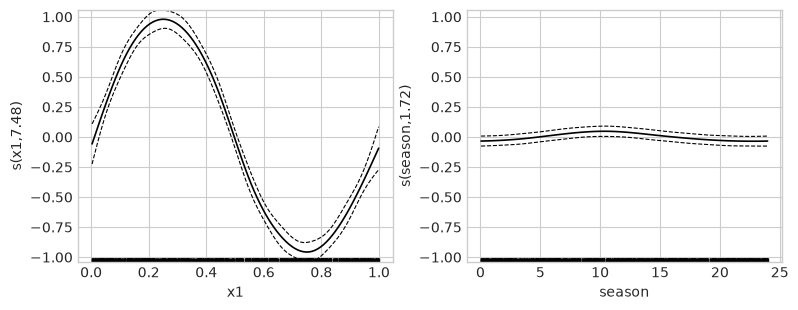

In [3]:
link = formula_gam.predict(data, type="link")
term_values = formula_gam.predict(data, type="terms", return_se=True)
Xp = formula_gam.lpmatrix(data)
formula_gam.plot(pages=1, se=True)

offset_gam = GAM(optimize_smoothing=True,
    formula="count ~ s(x1, bs='cr', k=8) + offset(log_exposure)",
    family="poisson",
    smoothing_method="ubre",
).fit(data=data)
display({"link shape": link.shape, "lpmatrix shape": Xp.shape, "offset AIC": offset_gam.aic()})


## 4. Formula language and smooth bases

Basis choice encodes geometry and boundary behavior. Shrinkage variants
add a penalty to the usual null space so an entire smooth can approach
zero. Tensor products are appropriate when predictors use different
units. Random and factor-specific smooths encode grouped structures.

The gallery is executable specification: constructing every object checks
that the installed parser recognizes the formula. Related bases share a
comparison row because their fitting workflow is identical.

Different bases span different candidate functions. Cubic regression splines
use piecewise cubic functions joined smoothly at knots. Thin-plate bases
provide a low-rank representation of a smoothness-penalized function space.
A cyclic basis additionally joins function values and derivatives at the
period boundary. Choose the boundary behavior from the meaning of the input,
then inspect the fitted curve rather than treating basis codes as arbitrary
hyperparameter labels.


In [4]:
formula_gallery = pd.DataFrame([
    ("B-spline derivatives", "bs", "y ~ s(x1, bs='bs', k=9, m=[3, 2])"),
    ("cubic regression", "cr / cs", "y ~ s(x1, bs='cr', k=9)"),
    ("cyclic cubic / P-spline", "cc / cp", "y ~ s(season, bs='cc', k=9)"),
    ("Duchon spline", "ds", "y ~ s(x1, x2, bs='ds', k=16)"),
    ("Gaussian-process smooth", "gp", "y ~ s(x1, x2, bs='gp', k=16)"),
    ("P-spline", "ps", "y ~ s(x1, bs='ps', k=9)"),
    ("spherical spline", "sos", "y ~ s(latitude, longitude, bs='sos', k=20)"),
    ("thin plate / shrinkage", "tp / ts", "y ~ s(x1, x2, bs='tp', k=16)"),
    ("Markov random field", "mrf", "y ~ s(region, bs='mrf', xt={'nb': neighbors})"),
    ("random effect", "re", "y ~ s(group, bs='re')"),
    ("factor-specific", "fs / sz", "y ~ s(group, x1, bs='fs', k=6, xt='cr')"),
    ("full tensor product", "te", "y ~ te(x1, x2, bs=['cr', 'ps'], k=[6, 6])"),
    ("pure tensor interaction", "ti", "y ~ s(x1) + s(x2) + ti(x1, x2, k=[6, 6])"),
], columns=["intended use", "basis", "formula"])

constructible = {
    row.basis: GAM(formula=row.formula)
    for row in formula_gallery.itertuples()
    if row.basis not in {"mrf", "sos"}
}
formula_gallery


,intended use,basis,formula
0,B-spline derivatives,bs,"y ~ s(x1, bs='bs', k=9, m=[3, 2])"
1,cubic regression,cr / cs,"y ~ s(x1, bs='cr', k=9)"
2,cyclic cubic / P-spline,cc / cp,"y ~ s(season, bs='cc', k=9)"
3,Duchon spline,ds,"y ~ s(x1, x2, bs='ds', k=16)"
4,Gaussian-process smooth,gp,"y ~ s(x1, x2, bs='gp', k=16)"
5,P-spline,ps,"y ~ s(x1, bs='ps', k=9)"
6,spherical spline,sos,"y ~ s(latitude, longitude, bs='sos', k=20)"
7,thin plate / shrinkage,tp / ts,"y ~ s(x1, x2, bs='tp', k=16)"
8,Markov random field,mrf,"y ~ s(region, bs='mrf', xt={'nb': neighbors})"
9,random effect,re,"y ~ s(group, bs='re')"


### 4.1 Parametric terms and smoothness sharing

Numeric and categorical parametric terms use ordinary model-matrix
columns. `x1:x2` is a parametric interaction. A shared `id=` pools basis
construction and smoothing parameters across compatible smooths.
`select=True` adds null-space selection penalties. `pc=` imposes a point
constraint such as $f(0)=0$. `sp=` fixes a term's smoothing parameter;
omitted values are selected when automatic smoothing is enabled.


In [5]:
language_examples = {
    "parametric": GAM(formula="y ~ x1 + group + x1:group"),
    "shared smoothing": GAM(formula="y ~ s(x1, bs='cr', id='shared') + s(x2, bs='cr', id='shared')"),
    "term selection": GAM(formula="y ~ s(x1, bs='ts', k=10)", select=True),
    "point constraint": GAM(formula="y ~ s(x1, bs='cr', k=10, pc=0.0)"),
    "fixed smoothing": GAM(formula="y ~ s(x1, bs='cr', k=10, sp=0.8)"),
}
sorted(language_examples)


['fixed smoothing',
 'parametric',
 'point constraint',
 'shared smoothing',
 'term selection']

## 5. Main effects, interactions, and grouped structure

A tensor interaction separates marginal trends from a residual surface.
Random effects use ridge penalties and partial pooling. Factor-specific
smooths allow a curve per group: `fs` applies per-level penalties, while
`sz` uses sum-to-zero constraints so deviations are interpreted around a
population curve. Shared smoothing parameters reduce the number of
hyperparameters when scientific reasoning supports common roughness.

A two-feature model can distinguish marginal and joint structure:

$$\eta(x,z)=\beta_0+f_1(x)+f_2(z)+f_{12}(x,z).$$

A tensor basis contains products $b_r(x)c_s(z)$. `te` represents a full tensor
smooth; `ti` removes the marginal spaces for a pure interaction alongside
main effects; `t2` uses a different tensor penalty decomposition. Their
penalties allow separate smoothing along the two input directions.
In a surface plot, a changing effect of $x$ across values of $z$ indicates
joint structure that a sum of two marginal curves cannot represent.

For a random group intercept $u_g$, the ridge penalty is proportional to
$\sum_g u_g^2$. This shrinks noisy group estimates toward a common baseline:
groups with less information are less free to follow their sample noise.



Family: gaussian
Link function: identity

Formula:
y ~ s(x1, bs='cr', k=8) + s(x2, bs='cr', k=8) + ti(x1, x2, bs=['cr', 'cr'], k=[5, 5]) + s(group, bs='re')

Parametric coefficients:
                 Estimate   Std. Error      t value     Pr(>|t|)    
(Intercept)        1.3142      0.27949        4.702    2.949e-06 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Approximate significance of smooth terms:
                      edf       Ref.df            F      p-value    
s(x1)              6.8425       6.9904       1105.9       <2e-16 ***
s(x2)               6.425       6.8818       409.75       <2e-16 ***
ti(x1, x2)         13.612       15.301       35.815       <2e-16 ***
s(group)           2.9975            3       1136.4       <2e-16 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

R-sq.(adj) = 0.935   Deviance explained = 93.7%
-REML = 112.76  Scale est. = 0.064656  n = 1000


GAMSummary(family_name='gaussian', link_name='identity', formula="y ~ s(x1, bs='cr', k=8) + s(x2, bs='cr', k=8) + ti(x1, x2, bs=['cr', 'cr'], k=[5, 5]) + s(group, bs='re')", p_coeff=array([1.31416152]), se=array([0.27948887, 0.03127925, 0.02444747, 0.0273586 , 0.02605454,
       0.0265529 , 0.02784709, 0.04440918, 0.03179474, 0.02362912,
       0.02626481, 0.02638058, 0.0259854 , 0.02703058, 0.04172103,
       0.07371505, 0.05861896, 0.06770518, 0.09303715, 0.05955363,
       0.04564192, 0.05494994, 0.07663399, 0.07221086, 0.05407529,
       0.06669274, 0.0861636 , 0.09693595, 0.07363777, 0.08796596,
       0.10977726, 0.27972856, 0.27971917, 0.27974328, 0.27972082]), p_t=array([4.70201735]), p_pv=array([2.94925139e-06]), p_table=             Estimate  Std. Error   t value  Pr(>|t|)
(Intercept)  1.314162    0.279489  4.702017  0.000003, pterms_table=Empty DataFrame
Columns: [label, df, wald_stat, p_value, test, covariance, dispersion]
Index: [], s_table=        label        edf     ref

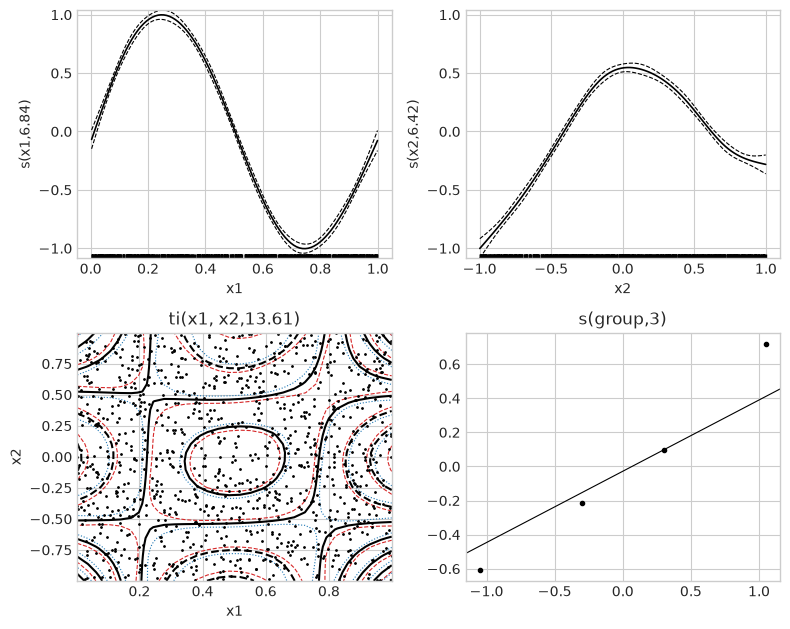

In [6]:
structured = GAM(
    optimize_smoothing=True,
    formula=(
        "y ~ s(x1, bs='cr', k=8) + s(x2, bs='cr', k=8) "
        "+ ti(x1, x2, bs=['cr', 'cr'], k=[5, 5]) + s(group, bs='re')"
    ),
    family="gaussian",
    smoothing_method="reml",
).fit(data=data)

structured_terms = structured.predict(data, type="terms")
structured.plot(pages=1, se=True, n2=30)
display(structured.summary())


### 5.1 Periodic, spatial, and spherical effects

Cyclic bases identify the endpoints of a known period. MRF smooths couple
adjacent regions through a graph Laplacian and require a neighbor graph,
polygons, or a supplied penalty. Spherical splines treat latitude and
longitude as coordinates on a sphere; ordinary planar smooths can distort
global geometry. These compact objects document the required formulas
without inventing a large external map dataset.

For a known period $P$, a cyclic effect satisfies $f(0)=f(P)$ together with
its required derivative constraints. That removes an artificial jump at the
boundary. For regional data, a graph penalty instead takes the form
$\sum_{g\sim h}(u_g-u_h)^2$, penalizing differences between neighboring
regions. Periodicity and adjacency encode different geometry, so their
smooths solve different modeling problems.


In [7]:
cyclic = GAM(formula="y ~ s(season, bs='cc', k=10)", optimize_smoothing=True, smoothing_method="reml").fit(data=data)
neighbors = {"north": ["central"], "central": ["north", "south"], "south": ["central"]}
spatial = GAM(formula="y ~ s(region, bs='mrf', xt={'nb': neighbors})")
spherical = GAM(formula="y ~ s(latitude, longitude, bs='sos', k=20)")

grid = pd.DataFrame({"season": np.linspace(0, 24, 200)})
cycle = cyclic.predict(grid)
display({"endpoint difference": float(abs(cycle[0] - cycle[-1])), "spatial formula": spatial.formula})


{'endpoint difference': 4.93116003585925e-08,
 'spatial formula': "y ~ s(region, bs='mrf', xt={'nb': neighbors})"}

## 6. Shape-constrained additive models

Shape constraints encode qualitative prior knowledge in the coefficient
parameterization. They are not post-fit clipping. First derivatives test
monotonicity; second derivatives test curvature. Positivity and anchoring
constrain function levels. Numeric-by and local bases apply restrictions
to varying-coefficient or subdomain effects. Bivariate codes constrain
directions or curvature of surfaces.

A monotone-increasing effect requires $f'(x)\geq0$; a convex effect requires
$f''(x)\geq0$. These restrictions narrow the set of admissible curves before
fitting. In a comparison plot, a constrained curve should obey the requested
shape even where an unconstrained curve follows local noise. The derivative
output checks that property directly. A wrong constraint can hide a real
turning point, so better visual regularity alone is not evidence for it.


In [8]:
shape_reference = pd.DataFrame([
    ("mpi", "monotone increasing"), ("mpd", "monotone decreasing"),
    ("cx", "convex"), ("cv", "concave"),
    ("micx", "increasing and convex"), ("micv", "increasing and concave"),
    ("mdcx", "decreasing and convex"), ("mdcv", "decreasing and concave"),
    ("po", "positive"), ("ipo", "increasing positive"), ("dpo", "decreasing positive"),
    ("miso", "anchored increasing"), ("mifo", "anchored decreasing"),
    ("mpiby / mpdby", "numeric-by monotonicity"),
    ("cxby / cvby / micxby / micvby / mdcxby / mdcvby", "numeric-by curvature"),
    ("lmpi / lipl", "local constraints"), ("cpop", "locally positive cyclic effect"),
    ("tedmi / tedmd", "tensor monotonicity"),
    ("temicx / temicv / tedecx / tedecv", "tensor monotonicity plus curvature"),
    ("tecxcx / tecvcv / tecxcv", "bivariate curvature"),
    ("tesmi1 / tesmd1 / tesmi2 / tesmd2", "single-direction monotonicity"),
    ("tismi / tismd", "tensor-interaction monotonicity"),
    ("tescx / tescv", "single-direction curvature"),
], columns=["basis code", "mathematical property"])
shape_reference


,basis code,mathematical property
0,mpi,monotone increasing
1,mpd,monotone decreasing
2,cx,convex
3,cv,concave
4,micx,increasing and convex
5,micv,increasing and concave
6,mdcx,decreasing and convex
7,mdcv,decreasing and concave
8,po,positive
9,ipo,increasing positive


In [9]:
shape_data = pd.DataFrame({"x": np.linspace(0, 1, n)})
shape_data["increasing"] = 1 + 3 * (1 - np.exp(-4 * shape_data["x"])) + rng.normal(0, 0.08, n)
shape_data["convex"] = 0.5 + 2.0 * shape_data["x"]**2 + rng.normal(0, 0.06, n)

monotone = GAM(
    formula="increasing ~ s(x, bs='mpi', k=10)",
    optimize_smoothing=False, smoothing_method="fixed", smoothing_params=[0.5],
).fit(data=shape_data)
convex = GAM(
    formula="convex ~ s(x, bs='cx', k=10)",
    optimize_smoothing=False, smoothing_method="fixed", smoothing_params=[0.5],
).fit(data=shape_data)

d1 = monotone.derivative(smooth_number=1, deriv=1).derivative
d2 = convex.derivative(smooth_number=1, deriv=2).derivative
display({"minimum first derivative": d1.min(), "minimum second derivative": d2.min()})


{'minimum first derivative': 0.2767806603754221,
 'minimum second derivative': 0.0}

## 7. Response families and links

The family determines support, variance, likelihood, deviance, residuals,
and inverse-link interpretation. The same smooth formula is therefore not
a substitute for choosing a scientifically appropriate distribution.
The examples below simulate responses on the required support and report
one family-appropriate check.

The mean link and response variance play different roles. Gaussian regression
with identity link models a real-valued mean; a Poisson model uses a positive
mean, commonly $\mu=\exp(\eta)$, with variance equal to that mean. A binomial
logit model maps $\eta$ to a probability. Thus the same one-unit predictor
change is a mean difference under identity, a multiplicative factor under
log, and an odds ratio under logit. Read fitted effects on their stated scale.


In [10]:
family_specs = {
    "Gaussian": ("y", "gaussian", "y ~ s(x1, bs='cr', k=8) + x2"),
    "Binomial": ("binary", "binomial", "binary ~ s(x1, bs='cr', k=8) + x2"),
    "Poisson": ("count", "poisson", "count ~ s(x1, bs='cr', k=8) + offset(log_exposure)"),
    "Gamma": ("gamma", {"name": "gamma", "link": "log"}, "gamma ~ s(x1, bs='cr', k=8)"),
    "Negative binomial": ("count", {"name": "nb"}, "count ~ s(x1, bs='cr', k=8) + offset(log_exposure)"),
    "Beta": ("beta", {"name": "betar", "theta": 8.0}, "beta ~ s(x1, bs='cr', k=8)"),
    "Tweedie": ("positive", {"name": "tweedie", "link": "log"}, "positive ~ s(x1, bs='cr', k=8)"),
    "Ordered categorical": ("ordinal", {"name": "ocat", "R": 4}, "ordinal ~ s(x1, bs='cr', k=8)"),
}

family_rows = []
family_models = {}
for label, (target, family, formula) in family_specs.items():
    method = "ubre" if label == "Poisson" else "reml"
    candidate = GAM(optimize_smoothing=True, formula=formula, family=family, smoothing_method=method).fit(data=data)
    family_models[label] = candidate
    fitted = np.asarray(candidate.predict(data, type="response"))
    family_rows.append({
        "family": label,
        "finite predictions": bool(np.isfinite(fitted).all()),
        "prediction minimum": float(np.min(fitted)),
        "deviance residual RMS": float(np.sqrt(np.mean(candidate.residuals(type="deviance")**2))),
    })
pd.DataFrame(family_rows)


,family,finite predictions,prediction minimum,deviance residual RMS
0,Gaussian,True,0.003075,0.687045
1,Binomial,True,0.428863,1.090234
2,Poisson,True,0.308971,1.028173
3,Gamma,True,1.504161,0.398371
4,Negative binomial,True,0.300673,1.027756
5,Beta,True,0.387892,1.105637
6,Tweedie,True,0.661798,1.032044
7,Ordered categorical,True,0.005172,1.435818


## 8. Selecting smoothness

Fixed smoothing is useful for controlled comparisons. GCV/Cp and UBRE
estimate predictive risk; ML, REML, and LAML use marginal-likelihood
criteria. REML is a strong default for many ordinary GAMs. Outer Newton
uses derivatives, BFGS is quasi-Newton, EFS is extended Fellner-Schall,
and the `optim` route can use methods such as L-BFGS-B where supported.
Availability depends jointly on family, criterion, and optimizer.

With smoothing fixed, coefficient fitting chooses a curve within a known
penalty. Automatic smoothness selection also estimates the strength of that
penalty. REML uses a marginal-likelihood view of penalized coefficients, while
GCV balances residual error against effective model complexity. Compare the
resulting effective degrees of freedom and curves as well as the criterion
value; a different optimizer is a computational route, not a different
scientific interpretation of the response.


In [11]:
smoothness_routes = [
    ("fixed", False, "fixed", "outer_newton", None),
    ("GCV/Cp", True, "gcv", "outer_newton", None),
    ("REML Newton", True, "reml", "outer_newton", None),
    ("REML BFGS", True, "reml", "bfgs", None),
    ("REML EFS", True, "reml", "efs", None),
    ("REML optim/L-BFGS-B", True, "reml", "optim", "L-BFGS-B"),
]

selection_rows = []
for label, optimize, method, optimizer, optim_method in smoothness_routes:
    started = time.perf_counter()
    kwargs = dict(
        formula="y ~ s(x1, bs='cr', k=10)", family="gaussian",
        optimize_smoothing=optimize, smoothing_method=method,
        smoothing_optimizer=optimizer,
    )
    if not optimize:
        kwargs["smoothing_params"] = [0.7]
    if optim_method is not None:
        kwargs["optim_method"] = optim_method
    candidate = GAM(**kwargs).fit(data=data)
    result = candidate.fit_result(include_covariances=False)
    selection_rows.append({
        "route": label,
        "fit seconds": time.perf_counter() - started,
        "EDF": result.edf_total,
        "criterion": result.criterion_value,
        "smoothing parameter": result.smoothing_params[0],
    })
selection_table = pd.DataFrame(selection_rows)
selection_table


,route,fit seconds,EDF,criterion,smoothing parameter
0,fixed,0.073929,9.937579,NaN,0.700000
1,GCV/Cp,0.267713,6.472198,0.516478,179.290953
2,REML Newton,0.681937,7.900331,1098.146692,50.342645
3,REML BFGS,1.433271,7.900485,1098.146692,50.335444
4,REML EFS,0.284750,7.900729,1098.146692,50.324072
5,REML optim/L-BFGS-B,1.129028,7.900477,1098.146692,50.335855


## 9. Inference and diagnostics

Confidence bands describe estimated-function uncertainty under the model;
residual plots examine distributional assumptions; derivatives describe
rates of change. ANOVA compares nested models when its assumptions apply.
AIC/BIC and log likelihood compare fit against complexity. Concurvity is
the smooth analogue of collinearity. `k_check` asks whether a chosen basis
dimension leaves residual pattern, and `gam_check` combines comparable
residual and basis-dimension checks with local optimizer information.

A small basis can leave systematic variation in nearby residuals even when
the optimizer converges. The basis-dimension check compares local residual
variation with overall residual variation; a low index and small simulated
p-value suggest investigating a larger basis. Concurvity asks a different
question: whether one smooth can be approximated by the others. Strong
concurvity can make individual curves unstable while predictions remain good.
Neither a large p-value nor a visually flat residual plot proves correctness.


In [12]:
good = GAM(formula="y ~ s(x1, bs='cr', k=12) + s(x2, bs='cr', k=9)", optimize_smoothing=True, smoothing_method="reml").fit(data=data)
poor = GAM(formula="y ~ s(x1, bs='cr', k=4)", optimize_smoothing=True, smoothing_method="reml").fit(data=data)

diagnostic_report = {
    "log likelihood": good.loglik(),
    "AIC": good.aic(),
    "BIC": good.bic(),
    "covariance shape": good.vcov().shape,
    "residual RMS": float(np.sqrt(np.mean(good.residuals(type="deviance")**2))),
}
poor_k = poor.k_check(subsample=min(len(data), 200), n_rep=20, seed=RANDOM_STATE)
poor_check = poor.gam_check(k_sample=min(len(data), 200), k_rep=20, seed=RANDOM_STATE)
concurvity = good.concurvity()
anova_table = poor.anova(good, test="F")
display(diagnostic_report)
display(poor_k)
display(anova_table)


{'log likelihood': -853.9890210117991,
 'AIC': 1739.8633443085075,
 'BIC': 1818.10597461386,
 'covariance shape': (20, 20),
 'residual RMS': 0.5683888427394008}

,k_prime,edf,k_index,p_value
label,,,,
s(x1),3,2.994198,1.08536,0.9


AnovaGAMComparison(family_name='gaussian', test='F', table=    Resid. Df  Resid. Dev         Df   Deviance          F        Pr(>F)
0  995.994251  510.307527        NaN        NaN        NaN           NaN
1  982.664004  323.065877  13.330247  187.24165  42.846178  2.811933e-88)

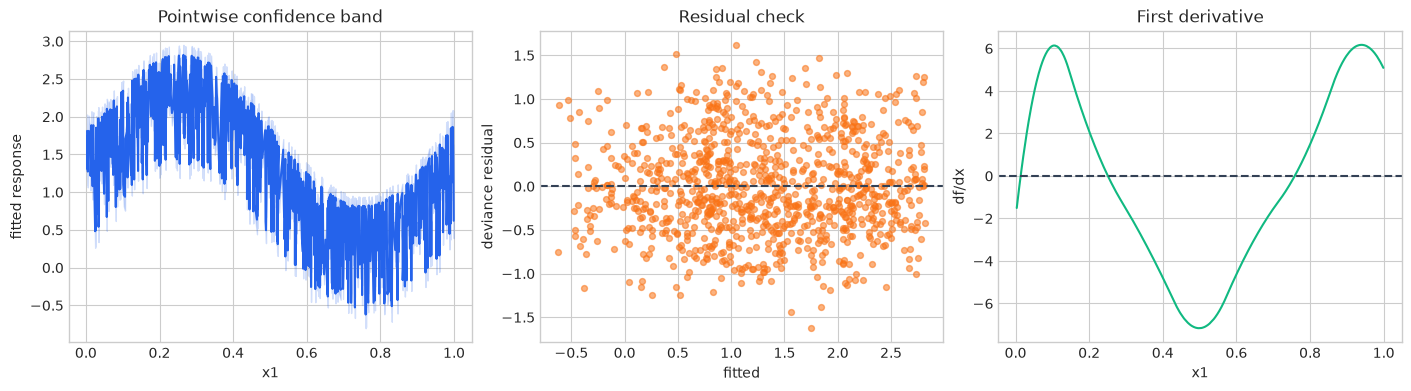

In [13]:
prediction, se = good.predict(data, type="response", return_se=True)
derivative_model = GAM(
    formula="y ~ s(x1, bs='ps', k=10)",
    optimize_smoothing=False,
    smoothing_method="fixed",
    smoothing_params=[0.7],
).fit(data=data)
derivative = derivative_model.derivative(data, smooth_number=1, deriv=1)
order = np.argsort(data["x1"].to_numpy())

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), constrained_layout=True)
axes[0].plot(data["x1"].to_numpy()[order], prediction[order], color=COLORS[0])
axes[0].fill_between(data["x1"].to_numpy()[order], (prediction - 2*se)[order], (prediction + 2*se)[order], color=COLORS[0], alpha=0.2)
axes[0].set(title="Pointwise confidence band", xlabel="x1", ylabel="fitted response")
axes[1].scatter(prediction, good.residuals(type="deviance"), s=18, alpha=0.55, color=COLORS[1])
axes[1].axhline(0, color="#334155", linestyle="--")
axes[1].set(title="Residual check", xlabel="fitted", ylabel="deviance residual")
axes[2].plot(data["x1"].to_numpy()[order], derivative.derivative[order], color=COLORS[2])
axes[2].axhline(0, color="#334155", linestyle="--")
axes[2].set(title="First derivative", xlabel="x1", ylabel="df/dx")
plt.show()
plt.close(fig)


## 10. Distributional GAMs

A GAMLSS model assigns one additive predictor to every distribution
parameter. For a normal model,

$$Y_i\mid x_i,z_i\sim N\{\mu(x_i),\sigma(z_i)^2\}.$$

Joint likelihood fitting differs from modeling squared residuals in a
second stage: location and scale are estimated together with their joint
covariance. Contributions reconstruct each raw parameter predictor.
Natural-parameter transforms then enforce domains such as $\sigma>0$.

For location-scale regression, each distribution parameter has an additive
predictor, $h_\mu(\mu_i)=\eta_{\mu i}$ and
$h_\sigma(\sigma_i)=\eta_{\sigma i}$. A normal observation contributes

$$-\log p(y_i\mid x_i)=\log\sigma_i+
\frac{(y_i-\mu_i)^2}{2\sigma_i^2}+\frac12\log(2\pi).$$

The likelihood balances accurate location against appropriate spread:
increasing $\sigma_i$ reduces the standardized squared residual but incurs
its own cost. Inspect mean and scale curves separately. A scale effect
describes response variability, not uncertainty in the estimated mean.


In [14]:
normal_lss = GAMLSS(
    formula=[
        "hetero ~ s(x1, bs='cr', k=9)",
        "~ s(x2, bs='cr', k=8)",
    ],
    family="normal",
    smoothing_method="ml",
).fit(data)

natural = normal_lss.predict(data)
raw = normal_lss.predict(data, raw=True)
point = normal_lss.predict_point(data)
components = normal_lss.predict_components(data)
components.validate_additive_reconstruction()
parameter_importance = normal_lss.term_importance(data)

lower = natural[:, 0] - 1.96 * natural[:, 1]
upper = natural[:, 0] + 1.96 * natural[:, 1]
coverage = np.mean((data["hetero"] >= lower) & (data["hetero"] <= upper))
display({
    "parameter names": normal_lss.parameter_names_,
    "raw shape": raw.shape,
    "natural shape": natural.shape,
    "minimum sigma": natural[:, 1].min(),
    "95% interval coverage": coverage,
})
display(parameter_importance)


{'parameter names': ('mu', 'sigma'),
 'raw shape': (1000, 2),
 'natural shape': (1000, 2),
 'minimum sigma': 0.27320485018364593,
 '95% interval coverage': 0.952}

,term,term_type,output,importance
0,"mu:s(x1, bs='cr', k=9)",main,0,0.656197
1,"sigma:s(x2, bs='cr', k=8)",main,1,0.179736
2,"mu:s(x1, bs='cr', k=9)",main,1,0.000000
3,"sigma:s(x2, bs='cr', k=8)",main,0,0.000000


### 10.1 Normal and Gamma location-scale models

`gaulss` returns natural $(\mu,\sigma)$ despite using a precision-related
scale predictor internally. `gammals` models a positive mean and scale;
both are transformed to remain positive. `predict(raw=True)` exposes the
additive predictors, `predict` returns natural parameters, and
`predict_point` returns the family-defined conditional mean.


In [15]:
gamma_lss = GAMLSS(
    formula=["gamma_lss ~ s(x1, bs='cr', k=8)", "~ 1"],
    family="gamma",
    smoothing_method="ml",
).fit(data)

gamma_parameters = gamma_lss.predict(data)
gamma_components = gamma_lss.predict_components(data)
gamma_components.validate_additive_reconstruction()
display({
    "normal NLL": normal_lss.evaluate(data, data["hetero"])["Negative Log-Likelihood"],
    "gamma NLL": gamma_lss.evaluate(data, data["gamma_lss"])["Negative Log-Likelihood"],
    "gamma parameters positive": bool((gamma_parameters > 0).all()),
})


{'normal NLL': 0.4771436068248171,
 'gamma NLL': 0.4268581136684536,
 'gamma parameters positive': True}

## 11. A practical workflow

Start with the response support and link, then specify scientifically
justified main effects and structures. Give bases enough capacity, select
smoothness, and inspect residuals, `k_check`, concurvity, and sensitivity
to plausible basis choices. Add interactions or distributional parameters
only when they answer a substantive question. Finally validate on held-out
data and persist the complete fitted object.
